# Customer Churn Prediction Project

#### Data Preparation

In [458]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [459]:
import kagglehub, os, pandas as pd

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))

In [460]:
df.head().T # transposing to see all the rows 

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


In [461]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [462]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [463]:
df.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges         object
churn                object
dtype: object

In [464]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')   

df.totalcharges = df.totalcharges.fillna(0)

In [465]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: object

In [466]:
df.churn = (df.churn == 'yes').astype(int)
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

#### Setting Up The Validation Framework

In [467]:
from sklearn.model_selection import train_test_split

In [468]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [469]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [470]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [471]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


In [472]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [473]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

### EDA

In [474]:
df_full_train = df_full_train.reset_index(drop=True)

In [475]:
# look at mising values 
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [476]:
df_full_train.churn.value_counts()

churn
0    4113
1    1521
Name: count, dtype: int64

In [477]:
df_full_train.churn.value_counts(normalize=True) # churn rate 

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [478]:
global_churn_rate = df_full_train.churn.mean() # also gives  churn rate 
round(global_churn_rate,2)

0.27

In [479]:
df_full_train.dtypes

customerid           object
gender               object
seniorcitizen         int64
partner              object
dependents           object
tenure                int64
phoneservice         object
multiplelines        object
internetservice      object
onlinesecurity       object
onlinebackup         object
deviceprotection     object
techsupport          object
streamingtv          object
streamingmovies      object
contract             object
paperlessbilling     object
paymentmethod        object
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [480]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [481]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [482]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

#### Feature Importance: Churn Rate And Risk Ratio

In [483]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472


... (22 outputs left out)



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


#### Feature Importance: Mutual Information

In [484]:
from sklearn.metrics import mutual_info_score

In [485]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [486]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

#### Feature Importance: Correlation

In [487]:
df_full_train[numerical].corrwith(df_full_train.churn)


tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [488]:
df_full_train.tenure.max()

72

In [489]:
df_full_train[df_full_train.tenure <= 2].churn.mean()

0.5953420669577875

In [490]:
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()

0.3994413407821229

In [491]:
df_full_train[df_full_train.tenure > 12].churn.mean()

0.17634908339788277

In [492]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

0.08795411089866156

In [493]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

0.18340943683409436

In [494]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()
# eda end 

0.32499341585462205

#### One-Hot Encoding

In [495]:
from sklearn.feature_extraction import DictVectorizer # it takes a dic and turn it into a vector 

In [496]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)


In [497]:
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

### Logistic Regression 

In [498]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [499]:
sigmoid(10000)

1.0

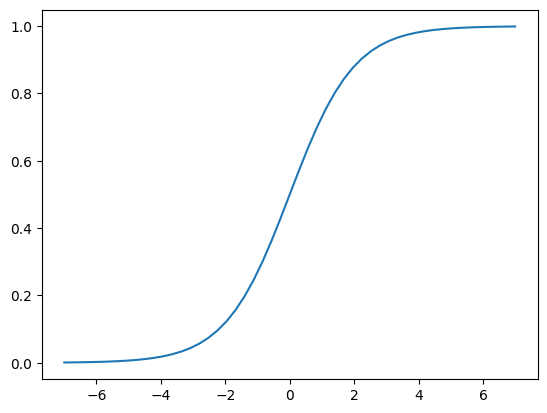

In [500]:
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

In [501]:
def logistic_regression(xi):
    score = w0 
    
    for i in range (len(w0)):
        score = score + xi[i] * w[i] 
    
    result = sigmoid(score)
    
    return result 

#### Training Logistic Regression with Scikit-Learn

In [502]:
from sklearn.linear_model import LogisticRegression

In [503]:
model = LogisticRegression()
model.fit(X_train, y_train)

/home/layanai/.pyenv/versions/ai/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [504]:
model.coef_[0].round(3)

array([ 0.475, -0.175, -0.408, -0.03 , -0.078,  0.063, -0.089, -0.081,
       -0.034, -0.073, -0.335,  0.317, -0.089,  0.004, -0.258,  0.142,
        0.009,  0.063, -0.089, -0.081,  0.266, -0.089, -0.284, -0.231,
        0.124, -0.166,  0.058, -0.087, -0.032,  0.07 , -0.059,  0.142,
       -0.249,  0.216, -0.12 , -0.089,  0.102, -0.071, -0.089,  0.052,
        0.213, -0.089, -0.232, -0.07 ,  0.   ])

In [505]:
model.predict(X_train) # gives churn hard predictions 

array([0, 1, 1, ..., 1, 0, 1])

In [506]:
model.predict_proba(X_train)[:,1] # gives churn soft predictions

array([0.09554691, 0.67925025, 0.63357442, ..., 0.53151756, 0.04252514,
       0.69868591])

In [507]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
11      2637-fkfsy
12      7228-omtpn
19      6711-fldfb
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 311, dtype: object

In [508]:
(y_val == churn_decision).mean() # accarecy, the model is correct 80% of the time 

0.8034066713981547

In [509]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

In [510]:
df_pred['correct'] = df_pred.prediction == df_pred.actual
df_pred.correct.mean()

0.8034066713981547

In [511]:
churn_decision.astype(int)

array([0, 0, 0, ..., 0, 1, 1])

In [512]:
df_pred

,probability,prediction,actual,correct
0,0.008985,0,0,True
1,0.204691,0,0,True
2,0.212399,0,0,True
3,0.542906,1,1,True
4,0.213938,0,0,True
...,...,...,...,...
1404,0.313551,0,0,True
1405,0.039321,0,1,False
1406,0.136306,0,0,True
1407,0.799699,1,1,True


#### Model Interpretation

In [513]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3))) 
# to see the waight fo each feature 

{'contract=month-to-month': 0.475,
 'contract=one_year': -0.175,
 'contract=two_year': -0.408,
 'dependents=no': -0.03,
 'dependents=yes': -0.078,
 'deviceprotection=no': 0.063,
 'deviceprotection=no_internet_service': -0.089,
 'deviceprotection=yes': -0.081,
 'gender=female': -0.034,
 'gender=male': -0.073,
 'internetservice=dsl': -0.335,
 'internetservice=fiber_optic': 0.317,
 'internetservice=no': -0.089,
 'monthlycharges': 0.004,
 'multiplelines=no': -0.258,
 'multiplelines=no_phone_service': 0.142,
 'multiplelines=yes': 0.009,
 'onlinebackup=no': 0.063,
 'onlinebackup=no_internet_service': -0.089,
 'onlinebackup=yes': -0.081,
 'onlinesecurity=no': 0.266,
 'onlinesecurity=no_internet_service': -0.089,
 'onlinesecurity=yes': -0.284,
 'paperlessbilling=no': -0.231,
 'paperlessbilling=yes': 0.124,
 'partner=no': -0.166,
 'partner=yes': 0.058,
 'paymentmethod=bank_transfer_(automatic)': -0.087,
 'paymentmethod=credit_card_(automatic)': -0.032,
 'paymentmethod=electronic_check': 0.07,
 

In [514]:
small = ['contract', 'tenure', 'monthlycharges']

dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [515]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

In [516]:
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

In [517]:
X_train_small = dv_small.transform(dicts_train_small)

model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

LogisticRegression()

In [518]:
w0 = model_small.intercept_[0]
w0 # bais

-2.477957595543144

In [519]:
sigmoid(-2.7)

0.06297335605699649

In [520]:
w = model_small.coef_[0]
dict(zip(dv_small.get_feature_names_out(), w.round(3))) # waights

{'contract=month-to-month': 0.971,
 'contract=one_year': -0.024,
 'contract=two_year': -0.948,
 'monthlycharges': 0.027,
 'tenure': -0.036}

In [521]:
-2.47 + (-0.949) + 30 * 0.027 + 24 * (-0.036)

-3.473

In [522]:
sigmoid(_)

0.030090303318277657

#### Using the Model

In [523]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.churn.values

In [524]:
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

/home/layanai/.pyenv/versions/ai/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [525]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')

In [526]:
X_test = dv.transform(dicts_test)

In [527]:
y_pred = model.predict_proba(X_val)[:, 1]

In [528]:
churn_decision = (y_pred >=0.5 )

In [529]:
(churn_decision == y_test ).mean()

0.6422995031937544

In [530]:
customer = dicts_test[10]
customer

{'gender': 'male',
 'seniorcitizen': 1,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'no',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'no',
 'onlinebackup': 'yes',
 'deviceprotection': 'no',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'mailed_check',
 'tenure': 32,
 'monthlycharges': 93.95,
 'totalcharges': 2861.45}

In [531]:
X_small = dv.transform([customer])

In [532]:
model.predict_proba(X_small)[0,1]

0.4977285760334902

In [533]:
y_test[10]

0

In [534]:
customer = dicts_test[12]
X_small = dv.transform([customer])
model.predict_proba(X_small)[0,1]

0.7379949035326234

In [535]:
y_test[12]

1

## Evaluation 

#### Accuracy 

In [536]:
len(y_val)

1409

In [537]:
from sklearn.metrics import accuracy_score

In [538]:
thresholds = np.linspace(0,1,21)

scores = []
for i in thresholds:
    score = accuracy_score(y_val, y_pred>= i)
    print("%.2f %.3f" % (i,score))
    scores.append(score)
scores    

# finding the best thrashold

0.00 0.274
0.05 0.505
0.10 0.600
0.15 0.664
0.20 0.725
0.25 0.749
0.30 0.767
0.35 0.777
0.40 0.794
0.45 0.797
0.50 0.804
0.55 0.815
0.60 0.805
0.65 0.789
0.70 0.778
0.75 0.745
0.80 0.737
0.85 0.727
0.90 0.726
0.95 0.726
1.00 0.726


[0.2739531582682754,
 0.5046132008516678,
 0.5997161107168204,
 0.6643009226401704,
 0.7246273953158269,
 0.7487579843860894,
 0.7665010645848119,
 0.7771469127040455,
 0.794180269694819,
 0.7970191625266146,
 0.8041163946061036,
 0.8147622427253371,
 0.8048261178140526,
 0.7885024840312278,
 0.7778566359119943,
 0.7452093683463449,
 0.7374024130589071,
 0.7267565649396736,
 0.7260468417317246,
 0.7260468417317246,
 0.7260468417317246]

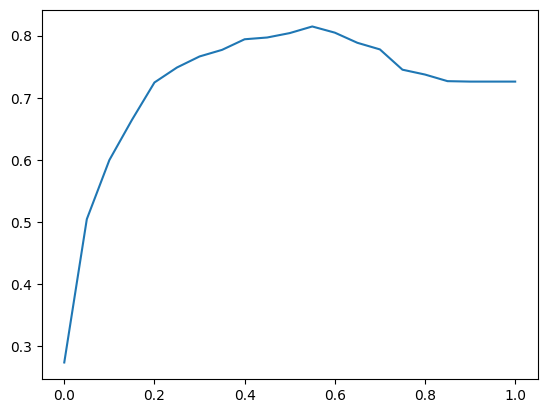

In [539]:
plt.plot(thresholds,scores) 

In [540]:
from collections import Counter 

In [541]:
Counter(y_pred >= 1.0)

Counter({False: 1409})

In [542]:
Counter(y_val)

Counter({0: 1023, 1: 386})

#### Confusion Table

In [543]:
actual_positive = (y_val ==1 )
actual_negative = (y_val == 0 )

In [550]:
t = 0.55
predict_positive = (y_pred >= t) 
predict_negative = (y_pred < t) 

In [551]:
TP = (actual_positive & predict_positive ).sum()
TN = (actual_negative & predict_negative).sum()


In [552]:
TP

197

In [553]:
FP = (actual_negative & predict_positive).sum()
FN = (actual_positive & predict_negative ).sum()

In [554]:
confusion_matrix = np.array([
    [TN, FP],   # actual: no churn
    [FN, TP]    # actual: churn
])
confusion_matrix

array([[951,  72],
       [189, 197]])

In [556]:
(confusion_matrix / confusion_matrix .sum()).round(2)

array([[0.67, 0.05],
       [0.13, 0.14]])

#### Precision and Recall

In [559]:
# Precision tells us how many posivie dissitions turnd out to be corect ot the fraction of posivie dissitions that are correct 
p = TP / (TP + FP)
p

0.7323420074349443

In [ ]:
# recall is the fraction of correctly identifaid positive examples 
r = TP / (TP+FN)


0.5103626943005182

#### ROC Curves

In [ ]:
# TPR, TRUE POSITIVE RATE, FRP FALSE NEGITIVE RATE 
tpr = TP / (TP+FN)
tpr # we want to makimize it 
# the fraction of tp over the total number of positive examples 

0.5103626943005182

In [ ]:
fpr = FP / (FP+TN)
fpr # we want ot minmize it 
# the fraction of all flase positive amung all positive examples, we want it to be as small as posible  

0.07038123167155426

In [568]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    TP = (predict_positive & actual_positive).sum()
    TN = (predict_negative & actual_negative).sum()

    FP = (predict_positive & actual_negative).sum()
    FN = (predict_negative & actual_positive).sum()
    
    scores.append((t, TP, FP, FN, TN))
    

columns = ['threshold', 'TP', 'FP', 'FN', 'TN']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['TPR'] = df_scores.TP / (df_scores.TP + df_scores.FN)
df_scores['FPR'] = df_scores.FP / (df_scores.FP + df_scores.TN)


In [570]:
df_scores[::10]

,threshold,TP,FP,FN,TN,TPR,FPR
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,367,545,19,478,0.950777,0.532747
20,0.2,334,336,52,687,0.865285,0.328446
30,0.3,295,238,91,785,0.764249,0.232649
40,0.4,258,162,128,861,0.668394,0.158358
50,0.5,215,105,171,918,0.556995,0.102639
60,0.6,162,51,224,972,0.419689,0.049853
70,0.7,91,18,295,1005,0.235751,0.017595
80,0.8,18,2,368,1021,0.046632,0.001955
90,0.9,0,0,386,1023,0.000000,0.000000


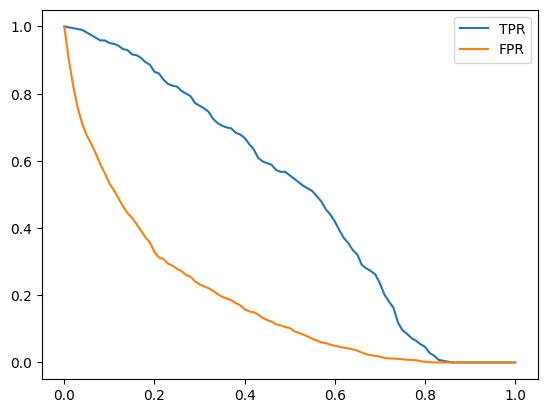

In [571]:
plt.plot(df_scores.threshold, df_scores['TPR'], label='TPR')
plt.plot(df_scores.threshold, df_scores['FPR'], label='FPR')
plt.legend()

In [ ]:
# random model 
# it makes disiones completlty randomily, so in this case it choses whether a customar will choren or not randomly 
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

((y_rand >= 0.5)==y_val).mean() 

0.5017743080198722

In [576]:
def TPR_FPR_dataframe(y_val,y_pred):

    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        TP = (predict_positive & actual_positive).sum()
        TN = (predict_negative & actual_negative).sum()

        FP = (predict_positive & actual_negative).sum()
        FN = (predict_negative & actual_positive).sum()
        
        scores.append((t, TP, FP, FN, TN))
        
    columns = ['threshold', 'TP', 'FP', 'FN', 'TN']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['TPR'] = df_scores.TP / (df_scores.TP + df_scores.FN)
    df_scores['FPR'] = df_scores.FP / (df_scores.FP + df_scores.TN)
        
    return df_scores

In [577]:
df_rand = TPR_FPR_dataframe(y_val,y_rand)

In [579]:
df_rand[::10]

,threshold,TP,FP,FN,TN,TPR,FPR
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


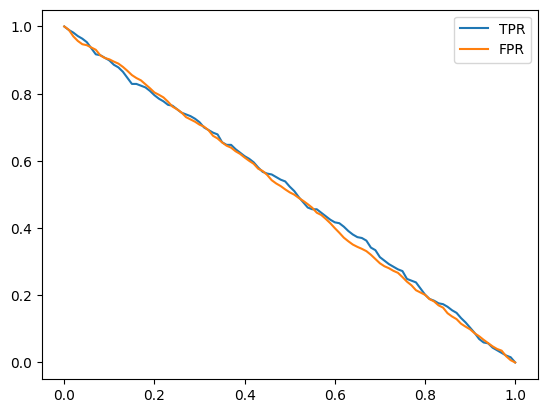

In [581]:
plt.plot(df_rand.threshold, df_rand['TPR'], label='TPR')
plt.plot(df_rand.threshold, df_rand['FPR'], label='FPR')
plt.legend()

In [ ]:
# ideal model, benchmark
# a model that gives the correct prediction for everyone

In [606]:
num_pos = (y_val == 1).sum()
num_neg = (y_val == 0).sum()
num_pos,num_neg

(386, 1023)

In [613]:
y_ideal = np.repeat([0,1],[num_neg,num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1])

In [614]:
y_ideal_pred = np.linspace(0,1,len(y_val))

In [615]:
1 - y_val.mean()

0.7260468417317246

In [616]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

1.0

In [619]:
df_ideal = TPR_FPR_dataframe (y_ideal,y_ideal_pred)

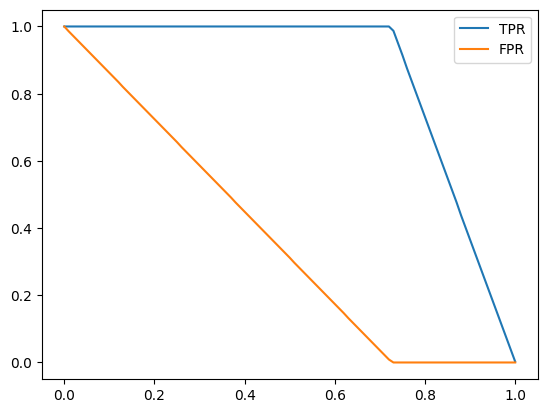

In [620]:
plt.plot(df_ideal.threshold, df_ideal['TPR'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['FPR'], label='FPR')
plt.legend()

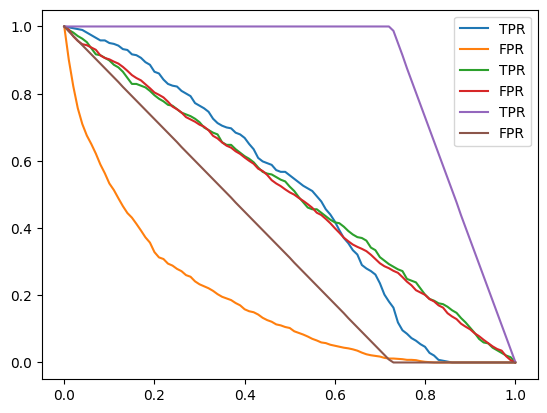

In [621]:
# every thing
plt.plot(df_scores.threshold, df_scores['TPR'], label='TPR')
plt.plot(df_scores.threshold, df_scores['FPR'], label='FPR')

plt.plot(df_rand.threshold, df_rand['TPR'], label='TPR')
plt.plot(df_rand.threshold, df_rand['FPR'], label='FPR')

plt.plot(df_ideal.threshold, df_ideal['TPR'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['FPR'], label='FPR')
plt.legend()

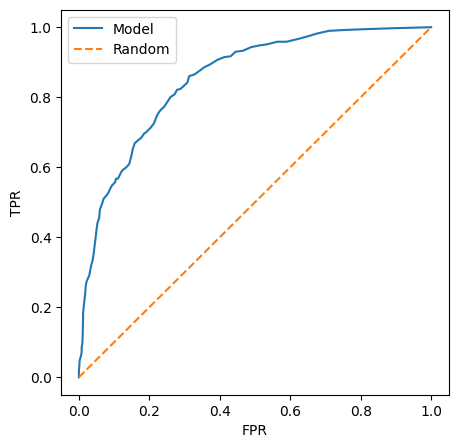

In [622]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.FPR, df_scores.TPR, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

##### ROC Curves with sklearn

In [ ]:
from sklearn.metrics import roc_curve 

In [624]:
FPR, TPR, thresholds = roc_curve(y_val, y_pred)

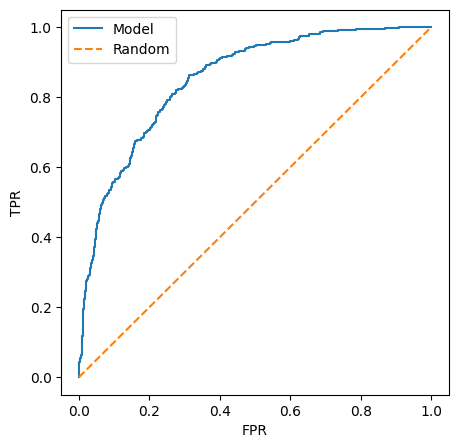

In [625]:
plt.figure(figsize=(5, 5))

plt.plot(FPR, TPR, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

#### ROC AUC

In [ ]:
from sklearn.metrics import auc # area under the cureve for any cureve 

In [627]:
auc(FPR,TPR)

0.851830185525656

In [629]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val,y_pred)

0.851830185525656

In [630]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [631]:
import random

n = 100000
success = 0 
 
for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success / n

0.8526

In [632]:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()


0.85408

####  Cross-Validation